# PASO 4: Modelos Supervizados - Clasificación

### 1\. Definición del Target y las Features

-   **Variable Objetivo (Target):** `sueldo_dolarizado` (Se trata de una clasificación binaria: `True` si el sueldo está dolarizado, `False` en caso contrario).

-   **Variables Predictoras (Features):** Se ajustan removiendo el target anterior y teniendo cuidado con el monto del salario (puede generar sobreajuste).

    -   *Numéricas clave:* `anos_de_experiencia`, `antiguedad_en_la_empresa_actual`, `anos_en_el_puesto_actual`, `tengo_edad`, `es_jerarquico`.

    -   *Categóricas clave:* `donde_estas_trabajando`, `dedicacion`, `tipo_de_contrato`, `modalidad_de_trabajo`, `contas_con_beneficios_adicionales`, `estas_buscando_trabajo`, `tenes_guardias`, `trabajo_de`, `seniority`, `plataformas_que_utilizas_en_tu_puesto_actual`, `lenguajes_de_programacion_o_tecnologias_que_utilices_en_tu_puesto_actual`, `frameworksherramientas_y_librerias_que_utilices_en_tu_puesto_actual`, `bases_de_datos`, `qa_testing`, `cantidad_de_personas_en_tu_organizacion`, `maximo_nivel_de_estudios`, `estado`, `carrera`, `genero`.

In [1]:
# Carga de librerías esenciales y DataFrame
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

# Métricas de clasificación
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Modelos de clasificación
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

# Importo el dataset limpio para trabajar en la clasificación
df = pd.read_csv('../data/dataset_clean.csv')

In [2]:
# Remueve cualquier tipo de advertencia de FutureWarning
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
# Selección de columnas por tipo
num_cols = [col for col in df.columns if pd.api.types.is_numeric_dtype(df[col])]
cat_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]

# Columnas que NUNCA deben ir como features
columnas_a_excluir = ["sueldo_dolarizado", "salario"]

# Las removemos de nuestras listas si es que están ahí
num_cols = [col for col in num_cols if col not in columnas_a_excluir]
cat_cols = [col for col in cat_cols if col not in columnas_a_excluir]

print("Cantidad de columnas numéricas:", len(num_cols))
print("Numéricas:", num_cols)
print("-" * 100)
print("Cantidad de columnas categóricas:", len(cat_cols))
print("Categóricas:", cat_cols)

Cantidad de columnas numéricas: 5
Numéricas: ['anos_de_experiencia', 'antiguedad_en_la_empresa_actual', 'anos_en_el_puesto_actual', 'tengo_edad', 'es_jerarquico']
----------------------------------------------------------------------------------------------------
Cantidad de columnas categóricas: 19
Categóricas: ['donde_estas_trabajando', 'dedicacion', 'tipo_de_contrato', 'modalidad_de_trabajo', 'contas_con_beneficios_adicionales', 'estas_buscando_trabajo', 'tenes_guardias', 'trabajo_de', 'seniority', 'plataformas_que_utilizas_en_tu_puesto_actual', 'lenguajes_de_programacion_o_tecnologias_que_utilices_en_tu_puesto_actual', 'frameworksherramientas_y_librerias_que_utilices_en_tu_puesto_actual', 'bases_de_datos', 'qa_testing', 'cantidad_de_personas_en_tu_organizacion', 'maximo_nivel_de_estudios', 'estado', 'carrera', 'genero']


### 2\. Modelado predictivo

Separación de entrenamiento y prueba, entrenamiento de modelos y comparación de resultados.

#### Distribución de Sueldos Dolarizados x Seniority/Edad

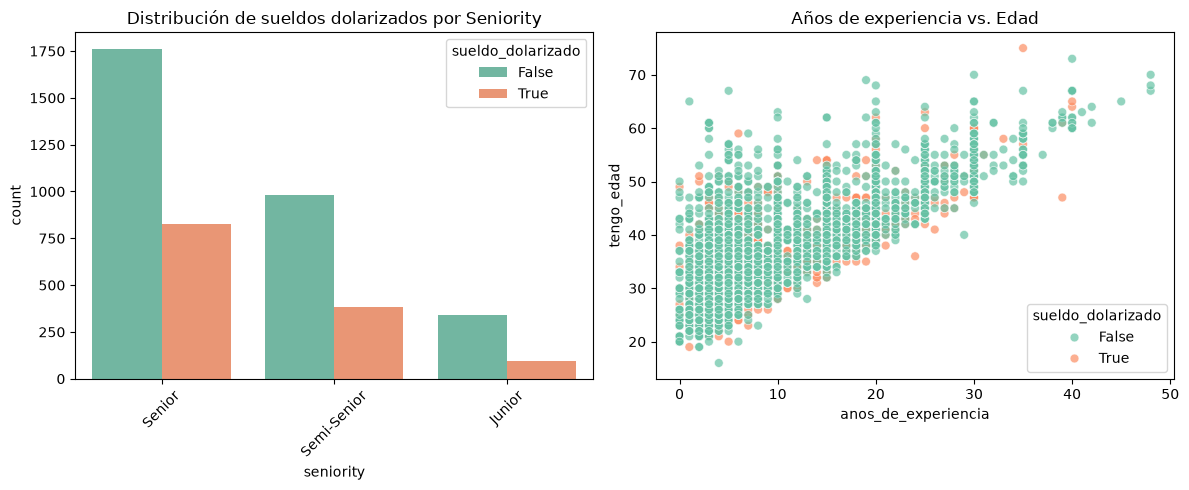

Media de medidas por condición de sueldo dolarizado:


,anos_de_experiencia,antiguedad_en_la_empresa_actual,anos_en_el_puesto_actual,tengo_edad
sueldo_dolarizado,,,,
False,10.1,5.0,3.8,37.4
True,9.8,3.5,3.2,36.3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Gráfico de barras: Cantidad de sueldos dolarizados por Seniority
sns.countplot(data=df, x="seniority", hue="sueldo_dolarizado", ax=axes[0], palette="Set2")
axes[0].set_title("Distribución de sueldos dolarizados por Seniority")
axes[0].tick_params(axis='x', rotation=45)

# 2. Gráfico de dispersión: Años de experiencia vs Edad
sns.scatterplot(
    data=df, 
    x="anos_de_experiencia", 
    y="tengo_edad",
    hue="sueldo_dolarizado", 
    palette="Set2", 
    ax=axes[1], 
    s=40,
    alpha=0.7
)
axes[1].set_title("Años de experiencia vs. Edad")

plt.tight_layout()
plt.show()

# 3. Tabla resumen
print("Media de medidas por condición de sueldo dolarizado:")
cols_numericas_resumen = ["anos_de_experiencia", "antiguedad_en_la_empresa_actual", "anos_en_el_puesto_actual", "tengo_edad"]
display(df.groupby("sueldo_dolarizado")[cols_numericas_resumen].mean().round(1))

 En general, no se observan grandes diferencias en los años de experiencia entre quienes cobran en dolares y quienes no. Sin embargo, quienes cobran en dolares tienen una menor antiguedad en la empresa actual. Esto podria indicar que el cobro en dolares no depende tanto de la experiencia acumulada, sino también de otros factores laborales.

#### Armamos conjunto de Train y Test (80% / 20%)

Se eligio una división del 80% para entrenamiento y del 20% test, ya que es una de las más utilizadas . De esta manera, el modelo puede aprender a partir de la mayor parte de los datos y evaluar su rendimiento con datos que no vio durante el entrenamiento.

In [5]:
X = df[num_cols + cat_cols]
y = df["sueldo_dolarizado"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train:", len(X_train), "| Test:", len(X_test))
print("\n% en train")
display((y_train.value_counts(normalize=True) * 100).round(1).to_frame("%"))
print("% en test")
display((y_test.value_counts(normalize=True) * 100).round(1).to_frame("%"))
print("Ambos conjuntos mantienen la proporción de clases del dataset original, gracias al parámetro 'stratify=y' en train_test_split.")

Train: 3509 | Test: 878

% en train


,%
sueldo_dolarizado,
False,70.3
True,29.7


% en test


,%
sueldo_dolarizado,
False,70.3
True,29.7


Ambos conjuntos mantienen la proporción de clases del dataset original, gracias al parámetro 'stratify=y' en train_test_split.


#### Armamos nuestro `preprocessor`

In [6]:
# Transformadores para columnas numéricas
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

# Transformadores para columnas categóricas
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        (
            'onehot',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
        ),
    ]
)

# Combinar en un ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols),
    ]
)

## Dummy Baseline vs Logistic Regression

Se utiliza el **dummy** como modelo de referencia para comparar sus resultados con los de la regresion logística y comprobar si esta logra aprender patrones útiles. 
 
La **matriz de confusion** permite ver cuántas predicciones son correctas y en cuáles se equivoca cada modelo, especialmente al identificar los sueldos dolarizados.

**Métricas a usar:**

| **Métrica** | **Qué calcula** | **Cómo la usamos en este caso** |
| --- | --- | --- |
| **Accuracy** (Exactitud) | El porcentaje total de predicciones correctas sobre el total de casos evaluados. | Mide el porcentaje general de sueldos clasificados correctamente (tanto los dolarizados como los no dolarizados). |
| **Precision** (Precisión) | Qué proporción de los casos predichos como positivos realmente lo son. | De todos los sueldos que el modelo etiqueta como "dolarizados", nos dice cuántos efectivamente lo son (minimiza los falsos positivos). |
| **Recall** (Exhaustividad) | Qué proporción de los casos positivos reales logró identificar el modelo. | De todos los sueldos que **realmente** están dolarizados en la realidad, nos muestra cuántos fue capaz de detectar el modelo (minimiza los falsos negativos). |
| **F1-Score** | La media armónica entre Precision y Recall, combinándolas en una sola medida. | Nos da un balance ideal cuando queremos evaluar el rendimiento general considerando tanto los falsos positivos como los falsos negativos (muy útil si hay desbalance de clases, y en este caso lo hay). |
| **ROC-AUC** | La capacidad general del modelo para distinguir entre ambas clases a distintos umbrales. Cuanto más cerca de 1, mejor. | Evalúa qué tan bien separa el modelo los sueldos dolarizados de los que no lo están, independientemente del umbral de decisión que elijamos. |
| **Matriz de confusión** | Una tabla que detalla los aciertos y errores del modelo divididos por cada clase. | Permite ver con claridad cuántos sueldos se acertaron o erraron en cada categoría (cuántos verdaderos/falsos dolarizados y no dolarizados tuvimos). |

MODELO: Dummy Classifier (Baseline)
Accuracy: 0.7027 | F1-Score: 0.0000 | ROC-AUC: 0.5000

Reporte de Clasificación (Dummy):
              precision    recall  f1-score   support

       False       0.70      1.00      0.83       617
        True       0.00      0.00      0.00       261

    accuracy                           0.70       878
   macro avg       0.35      0.50      0.41       878
weighted avg       0.49      0.70      0.58       878

MODELO: Logistic Regression
Accuracy: 0.7836 | F1-Score: 0.5796 | ROC-AUC: 0.7664

Reporte de Clasificación (Logistic Regression):
              precision    recall  f1-score   support

       False       0.81      0.90      0.85       617
        True       0.69      0.50      0.58       261

    accuracy                           0.78       878
   macro avg       0.75      0.70      0.72       878
weighted avg       0.77      0.78      0.77       878



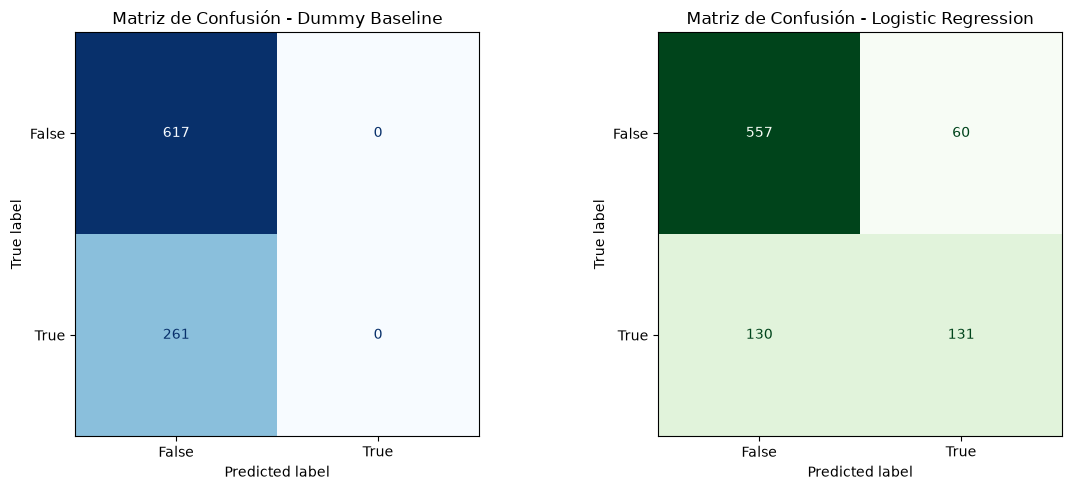


TABLA RESUMEN DE ESTADÍSTICAS COMPARATIVAS


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Modelo,,,,,
Dummy Baseline,0.702733,0.000000,0.000000,0.000000,0.500000
Logistic Regression,0.783599,0.685864,0.501916,0.579646,0.766433



CONCLUSIÓN DEL ANÁLISIS

Clase desbalanceada detectada: Los sueldos no dolarizados son clara mayoría en el dataset.

1. El 'Dummy Baseline' (que predice ciegamente la clase mayoritaria) obtiene un Accuracy engañosamente alto, 
   pero su F1-Score y su ROC-AUC (0.5000) demuestran que es un modelo nulo que no aporta información predictiva real.
2. La 'Logistic Regression' supera significativamente al baseline, logrando capturar patrones ocultos 
   gracias a las variables transformadas en el Pipeline. 
3. Como hay muchas más respuestas de una clase que de la otra, no alcanza con mirar solamente 
   el Accuracy. También tenemos que revisar el F1-Score y la matriz de confusión para entender 
   si el modelo logra identificar los sueldos dolarizados o si se equivoca con frecuencia 
   al intentar reconocer esta clase menos común.



In [7]:
# ==========================================
# 1. ENTRENAMIENTO Y EVALUACIÓN: DUMMY BASELINE
# ==========================================
print("=" * 60)
print("MODELO: Dummy Classifier (Baseline)")
print("=" * 60)

# Pipeline para Dummy
loro = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", DummyClassifier(strategy="most_frequent"))]
)

loro.fit(X_train, y_train)
y_pred_dummy = loro.predict(X_test)
y_proba_dummy = loro.predict_proba(X_test)[:, 1]

# Métricas Dummy
acc_dummy = accuracy_score(y_test, y_pred_dummy)
prec_dummy = precision_score(y_test, y_pred_dummy, zero_division=0)
rec_dummy = recall_score(y_test, y_pred_dummy, zero_division=0)
f1_dummy = f1_score(y_test, y_pred_dummy, zero_division=0)
roc_dummy = roc_auc_score(y_test, y_proba_dummy)

print(f"Accuracy: {acc_dummy:.4f} | F1-Score: {f1_dummy:.4f} | ROC-AUC: {roc_dummy:.4f}\n")
print("Reporte de Clasificación (Dummy):")
print(classification_report(y_test, y_pred_dummy, zero_division=0))
cm_dummy = confusion_matrix(y_test, y_pred_dummy)


# ==========================================
# 2. ENTRENAMIENTO Y EVALUACIÓN: REGRESIÓN LOGÍSTICA
# ==========================================
print("=" * 60)
print("MODELO: Logistic Regression")
print("=" * 60)

# Pipeline para Regresión Logística
pipe_lr = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", LogisticRegression(max_iter=1000, random_state=42))]
)

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)
y_proba_lr = pipe_lr.predict_proba(X_test)[:, 1]

# Métricas Regresión Logística
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr, zero_division=0)
rec_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
roc_lr = roc_auc_score(y_test, y_proba_lr)

print(f"Accuracy: {acc_lr:.4f} | F1-Score: {f1_lr:.4f} | ROC-AUC: {roc_lr:.4f}\n")
print("Reporte de Clasificación (Logistic Regression):")
print(classification_report(y_test, y_pred_lr, zero_division=0))
cm_lr = confusion_matrix(y_test, y_pred_lr)


# ==========================================
# 3. VISUALIZACIÓN: MATRICES DE CONFUSIÓN LADO A LADO
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: Dummy
disp_dummy = ConfusionMatrixDisplay(confusion_matrix=cm_dummy, display_labels=loro.classes_)
disp_dummy.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Matriz de Confusión - Dummy Baseline")

# Gráfico 2: Regresión Logística
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=pipe_lr.classes_)
disp_lr.plot(ax=axes[1], cmap="Greens", values_format="d", colorbar=False)
axes[1].set_title("Matriz de Confusión - Logistic Regression")

plt.tight_layout()
plt.show()


# ==========================================
# 4. TABLA RESUMEN DE ESTADÍSTICAS COMPARATIVAS
# ==========================================
df_resumen = pd.DataFrame({
    "Modelo": ["Dummy Baseline", "Logistic Regression"],
    "Accuracy": [acc_dummy, acc_lr],
    "Precision": [prec_dummy, prec_lr],
    "Recall": [rec_dummy, rec_lr],
    "F1-Score": [f1_dummy, f1_lr],
    "ROC-AUC": [roc_dummy, roc_lr]
}).set_index("Modelo")

print("\n" + "=" * 60)
print("TABLA RESUMEN DE ESTADÍSTICAS COMPARATIVAS")
print("=" * 60)
display(df_resumen)


# ==========================================
# 5. CONCLUSIÓN MEJORADA
# ==========================================
print("\n" + "=" * 60)
print("CONCLUSIÓN DEL ANÁLISIS")
print("=" * 60)
print(f"""
Clase desbalanceada detectada: Los sueldos no dolarizados son clara mayoría en el dataset.

1. El 'Dummy Baseline' (que predice ciegamente la clase mayoritaria) obtiene un Accuracy engañosamente alto, 
   pero su F1-Score y su ROC-AUC (0.5000) demuestran que es un modelo nulo que no aporta información predictiva real.
2. La 'Logistic Regression' supera significativamente al baseline, logrando capturar patrones ocultos 
   gracias a las variables transformadas en el Pipeline. 
3. Como hay muchas más respuestas de una clase que de la otra, no alcanza con mirar solamente 
   el Accuracy. También tenemos que revisar el F1-Score y la matriz de confusión para entender 
   si el modelo logra identificar los sueldos dolarizados o si se equivoca con frecuencia 
   al intentar reconocer esta clase menos común.
""")

## Decision Tree Classifier

El **DecisionTree** busca predecir si el sueldo está dolarizado mediante reglas y preguntas sucesivas que aprende a partir de los datos disponibles. 

MODELO: Decision Tree Classifier
Accuracy: 0.7540 | F1-Score: 0.5798 | ROC-AUC: 0.7012

Reporte de Clasificación (Decision Tree):
              precision    recall  f1-score   support

       False       0.82      0.83      0.83       617
        True       0.59      0.57      0.58       261

    accuracy                           0.75       878
   macro avg       0.70      0.70      0.70       878
weighted avg       0.75      0.75      0.75       878



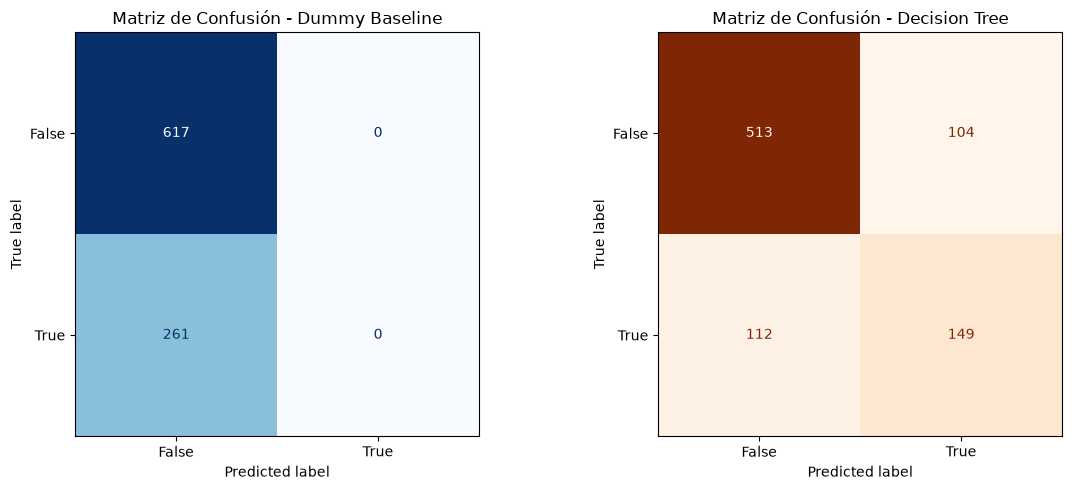


TABLA RESUMEN DE ESTADÍSTICAS COMPARATIVAS


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Modelo,,,,,
Dummy Baseline,0.702733,0.000000,0.000000,0.000000,0.500000
Decision Tree,0.753986,0.588933,0.570881,0.579767,0.701162



CONCLUSIÓN DEL MODELO (DECISION TREE)
El árbol de decisión simple logra capturar patrones no lineales en los datos, superando al Baseline en métricas como el ROC-AUC y F1-Score.


In [8]:
# ==========================================
# 1. ENTRENAMIENTO Y EVALUACIÓN: DECISION TREE
# ==========================================
print("=" * 60)
print("MODELO: Decision Tree Classifier")
print("=" * 60)

# Pipeline para Decision Tree
model_dtc = Pipeline(
    steps=[
        ("preprocessor", preprocessor), 
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]
)

model_dtc.fit(X_train, y_train)
y_pred_dt = model_dtc.predict(X_test)
y_proba_dt = model_dtc.predict_proba(X_test)[:, 1]

# Métricas Decision Tree
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt, zero_division=0)
rec_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)
roc_dt = roc_auc_score(y_test, y_proba_dt)

print(f"Accuracy: {acc_dt:.4f} | F1-Score: {f1_dt:.4f} | ROC-AUC: {roc_dt:.4f}\n")
print("Reporte de Clasificación (Decision Tree):")
print(classification_report(y_test, y_pred_dt, zero_division=0))
cm_dt = confusion_matrix(y_test, y_pred_dt)


# ==========================================
# 2. VISUALIZACIÓN: MATRICES DE CONFUSIÓN (Dummy vs Decision Tree)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: Reutilizamos la matriz de confusión del Dummy ya calculada antes (`cm_dummy`)
disp_dummy = ConfusionMatrixDisplay(confusion_matrix=cm_dummy, display_labels=loro.classes_)
disp_dummy.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Matriz de Confusión - Dummy Baseline")

# Gráfico 2: Nuevo gráfico de Decision Tree
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=model_dtc.classes_)
disp_dt.plot(ax=axes[1], cmap="Oranges", values_format="d", colorbar=False)
axes[1].set_title("Matriz de Confusión - Decision Tree")

plt.tight_layout()
plt.show()


# ==========================================
# 3. TABLA RESUMEN CONSOLIDADA (Dummy + Decision Tree)
# ==========================================
# Actualizamos la tabla acumulando los modelos analizados hasta ahora
df_resumen_actualizado = pd.DataFrame({
    "Modelo": ["Dummy Baseline", "Decision Tree"],
    "Accuracy": [acc_dummy, acc_dt],
    "Precision": [prec_dummy, prec_dt],
    "Recall": [rec_dummy, rec_dt],
    "F1-Score": [f1_dummy, f1_dt],
    "ROC-AUC": [roc_dummy, roc_dt]
}).set_index("Modelo")

print("\n" + "=" * 60)
print("TABLA RESUMEN DE ESTADÍSTICAS COMPARATIVAS")
print("=" * 60)
display(df_resumen_actualizado)


# ==========================================
# 4. CONCLUSIÓN SOBRE EL ÁRBOL DE DECISIÓN
# ==========================================
print("\n" + "=" * 60)
print("CONCLUSIÓN DEL MODELO (DECISION TREE)")
print("=" * 60)
print(f"""El árbol de decisión simple logra capturar patrones no lineales en los datos, superando al Baseline en métricas como el ROC-AUC y F1-Score.""")

## Stratified K-Fold DecisionTreeClassifier vs Dummy

Utilizamos la **validacion cruzada estratificada** para comparar el rendimiento del arbol de decisión con el modelo **Dummy**en diferentes particiones de los datos. Esto permite evaluar si el arbol obtiene resultados coherentes

In [9]:
# 1. Configurar la Validación Cruzada Estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definir las métricas que queremos evaluar
scoring_metrics = ["accuracy", "f1", "roc_auc"]

# Evaluar ambos modelos con cross_validate en un solo paso
print("Evaluando Dummy Classifier (loro) con StratifiedKFold...")
cv_dummy = cross_validate(loro, X_train, y_train, cv=cv, scoring=scoring_metrics)

print("Evaluando Decision Tree (model_dtc) con StratifiedKFold...")
cv_arbol = cross_validate(model_dtc, X_train, y_train, cv=cv, scoring=scoring_metrics)

# Imprimir resultados organizados con su media y desviación estándar
print("\n" + "=" * 50)
print("RESULTADOS VALIDACIÓN CRUZADA ESTRATIFICADA (SKF)")
print("=" * 50)

print(f"Dummy Accuracy:  {cv_dummy['test_accuracy'].mean():.3f} ± {cv_dummy['test_accuracy'].std():.3f}")
print(f"Dummy F1-Score:  {cv_dummy['test_f1'].mean():.3f} ± {cv_dummy['test_f1'].std():.3f}")
print(f"Dummy ROC-AUC:   {cv_dummy['test_roc_auc'].mean():.3f} ± {cv_dummy['test_roc_auc'].std():.3f}\n")

print(f"Árbol Accuracy:  {cv_arbol['test_accuracy'].mean():.3f} ± {cv_arbol['test_accuracy'].std():.3f}")
print(f"Árbol F1-Score:  {cv_arbol['test_f1'].mean():.3f} ± {cv_arbol['test_f1'].std():.3f}")
print(f"Árbol ROC-AUC:   {cv_arbol['test_roc_auc'].mean():.3f} ± {cv_arbol['test_roc_auc'].std():.3f}")

# Comparativa lógica final
print("\n" + "=" * 50)
print("CONCLUSIÓN DE LA COMPARATIVA")
print("=" * 50)
if cv_arbol['test_roc_auc'].mean() > cv_dummy['test_roc_auc'].mean():
    print("¡El árbol supera al dummy en ROC-AUC! El modelo tiene sentido predictivo real.")
else:
    print("Alerta: El árbol no le gana al dummy en ROC-AUC en promedio.")

Evaluando Dummy Classifier (loro) con StratifiedKFold...
Evaluando Decision Tree (model_dtc) con StratifiedKFold...

RESULTADOS VALIDACIÓN CRUZADA ESTRATIFICADA (SKF)
Dummy Accuracy:  0.703 ± 0.001
Dummy F1-Score:  0.000 ± 0.000
Dummy ROC-AUC:   0.500 ± 0.000

Árbol Accuracy:  0.730 ± 0.012
Árbol F1-Score:  0.507 ± 0.022
Árbol ROC-AUC:   0.654 ± 0.013

CONCLUSIÓN DE LA COMPARATIVA
¡El árbol supera al dummy en ROC-AUC! El modelo tiene sentido predictivo real.


> **Conclusion:** En la validacion cruzada, el arbol de decision obtuvo mejores resultados que el **Dummy**, especialmente en `F1-Score` y `ROC-AUC`. y los desvios son bajos, por lo que sus resultados son relativamente estables entre los grupos. Esto indica que el arbol logra  predecir los sueldos dolarizados.

#### Búsqueda de Hiperparámetros y Selección del Mejor `max_depth`

In [10]:
filas_d = []

# Probamos distintas profundidades para encontrar la mejor mediante Validación Cruzada
for d in [4, 8, 12]:
    m = Pipeline([
        ("prep", preprocessor),  # Reutilizamos el preprocesador general
        ("modelo", DecisionTreeClassifier(max_depth=d, random_state=42)),
    ])
    
    acc = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy")
    f1 = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro")
    
    filas_d.append({
        "max_depth": d,
        "cv_acc": acc.mean(),
        "cv_acc_std": acc.std(),
        "cv_f1": f1.mean(),
    })

# Convertimos los resultados a DataFrame para visualizarlos claramente
tab_d = pd.DataFrame(filas_d)
print("Resultados de la búsqueda por Validación Cruzada:")
display(tab_d.round(3))

# Criterio de parsimonia: elegimos la profundidad óptima priorizando la más simple si el rendimiento es muy parecido
mejor = tab_d["cv_acc"].max()
candidatos = tab_d[tab_d["cv_acc"] >= mejor - 0.01]
depth_elegido = int(candidatos["max_depth"].min())

print(f"Depth elegido con CV: {depth_elegido}")

Resultados de la búsqueda por Validación Cruzada:


,max_depth,cv_acc,cv_acc_std,cv_f1
0,4,0.772,0.008,0.670
1,8,0.763,0.011,0.669
2,12,0.761,0.012,0.672


Depth elegido con CV: 4


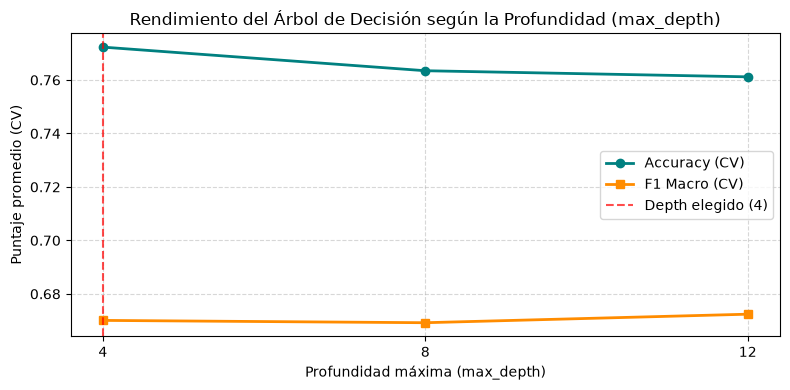

In [11]:
plt.figure(figsize=(8, 4))

# Línea de Accuracy en validación cruzada
plt.plot(
    tab_d["max_depth"],
    tab_d["cv_acc"],
    marker="o",
    linewidth=2,
    label="Accuracy (CV)",
    color="teal",
)

# Línea de F1 Macro en validación cruzada
plt.plot(
    tab_d["max_depth"],
    tab_d["cv_f1"],
    marker="s",
    linewidth=2,
    label="F1 Macro (CV)",
    color="darkorange",
)

# Marcar con una línea vertical la profundidad que elegimos automáticamente
plt.axvline(
    x=depth_elegido,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Depth elegido ({depth_elegido})",
)

plt.title("Rendimiento del Árbol de Decisión según la Profundidad (max_depth)")
plt.xlabel("Profundidad máxima (max_depth)")
plt.ylabel("Puntaje promedio (CV)")
plt.xticks(tab_d["max_depth"])  # Asegura que muestre solo 4, 8, 12
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

> **Conclusion:** La profundidad max_depth=4 se elige porque alcanza un buen rendimiento sin necesidad de aumentar la complejidad del arbol. Al probar profundidades mayores, el `Accuracy` no muestra una mejora significativa y el `F1-Score` se mantiene practicamente igual. Por eso, se prefiere el arbol más simple.  

#### Entrenamiento del Modelo Definitivo y Evalucación en TEST

In [12]:
# 1. Entrenar el modelo final con todo el conjunto de entrenamiento usando el parámetro ganador
arbol_test = Pipeline([
    ("prep", preprocessor),
    ("modelo", DecisionTreeClassifier(max_depth=depth_elegido, random_state=42)),
])

arbol_test.fit(X_train, y_train)

# 2. Generar predicciones a ciegas sobre el conjunto de prueba (Test)
pred_c = arbol_test.predict(X_test)
pred_dummy = loro.predict(X_test)  # Baseline de referencia

# 3. Mostrar resultados finales
print("=" * 50)
print("EVALUACIÓN FINAL EN CONJUNTO DE TEST (Datos nunca antes vistos)")
print("=" * 50)
print(f"TEST Accuracy Dummy Baseline : {accuracy_score(y_test, pred_dummy):.3f}")
print(f"TEST Accuracy Árbol Final  : {accuracy_score(y_test, pred_c):.3f}")

EVALUACIÓN FINAL EN CONJUNTO DE TEST (Datos nunca antes vistos)
TEST Accuracy Dummy Baseline : 0.703
TEST Accuracy Árbol Final  : 0.782


> **Conclusion:** El **arbol de decision** final obtuvo un `Accuracy` del 78,2 % en el conjunto de test, superando al 70,3 % del modelo **Dummy Baseline**. Esto indica que el arbol logra realizar más predicciones correctas sobre datos que no vio durante el entrenamiento. 

REPORTE DE CLASIFICACIÓN - DUMMY BASELINE (TEST)
                      precision    recall  f1-score   support

Sueldo NO Dolarizado       0.70      1.00      0.83       617
   Sueldo Dolarizado       0.00      0.00      0.00       261

            accuracy                           0.70       878
           macro avg       0.35      0.50      0.41       878
        weighted avg       0.49      0.70      0.58       878

REPORTE DE CLASIFICACIÓN - ÁRBOL FINAL (max_depth=4) (TEST)
                      precision    recall  f1-score   support

Sueldo NO Dolarizado       0.80      0.93      0.86       617
   Sueldo Dolarizado       0.72      0.44      0.54       261

            accuracy                           0.78       878
           macro avg       0.76      0.68      0.70       878
        weighted avg       0.77      0.78      0.76       878



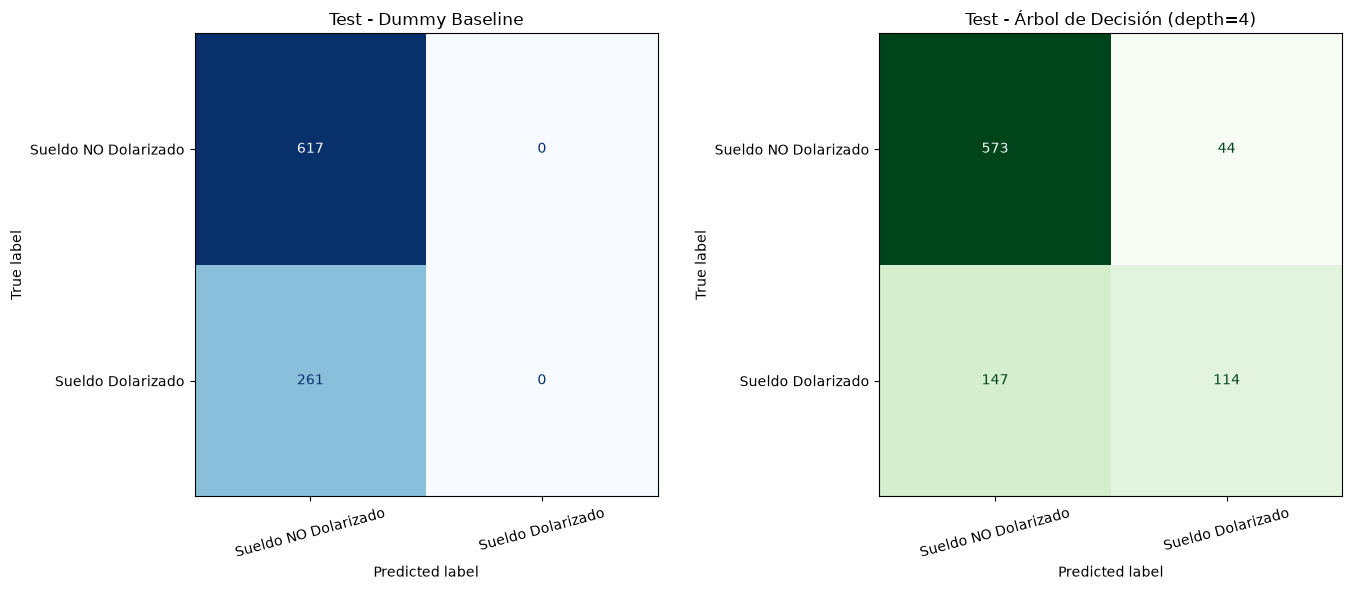

In [13]:
# Definimos los nombres descriptivos para las clases de la variable objetivo
nombres_clases = ["Sueldo NO Dolarizado", "Sueldo Dolarizado"]

# 1. Generar reportes detallados en consola (Precision, Recall, F1-Score)
print("=" * 60)
print("REPORTE DE CLASIFICACIÓN - DUMMY BASELINE (TEST)")
print("=" * 60)
print(classification_report(y_test, pred_dummy, target_names=nombres_clases, zero_division=0))

print("=" * 60)
print(f"REPORTE DE CLASIFICACIÓN - ÁRBOL FINAL (max_depth={depth_elegido}) (TEST)")
print("=" * 60)
print(classification_report(y_test, pred_c, target_names=nombres_clases, zero_division=0))

# 2. Calcular matrices de confusión para ambos
cm_dummy_test = confusion_matrix(y_test, pred_dummy)
cm_arbol_test = confusion_matrix(y_test, pred_c)

# 3. Visualizar las matrices de confusión lado a lado con etiquetas personalizadas
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Dummy Baseline
disp_dummy = ConfusionMatrixDisplay(confusion_matrix=cm_dummy_test, display_labels=nombres_clases)
disp_dummy.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Test - Dummy Baseline")
# Rotamos las etiquetas del eje X si son muy largas para que no se encimen
axes[0].tick_params(axis='x', rotation=15)

# Gráfico 2: Árbol Final
disp_arbol = ConfusionMatrixDisplay(confusion_matrix=cm_arbol_test, display_labels=nombres_clases)
disp_arbol.plot(ax=axes[1], cmap="Greens", values_format="d", colorbar=False)
axes[1].set_title(f"Test - Árbol de Decisión (depth={depth_elegido})")
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

> **Conclusión**: El **árbol de decisión** (`max_depth=4`) supera al **Dummy Baseline**, alcanzando un `Accuracy` global del 78%. Si bien el modelo logra identificar el 44 % de los sueldos dolarizados con una precisión aceptable (0.72) y un **F1-score de 0.54**, su rendimiento se ve limitado por el desbalance de clases, dejando sin detectar a más de la mitad de los casos reales en dólares.

#### Variables con Mayor peso en Clasificación
* `tipo_de_contrato_Contractor` (71.5%) Podriamos verlo como que ser Contractor es casi sinónimo de trabajar para el exterior y cobrar en moneda extranjera.
* `100% Remoto` (15.3%) Contratos internacionales exigen modalidad remota normalmente.

In [14]:
# 1. Extraer los nombres de las columnas transformadas (incluyendo las expandidas por OneHotEncoder)
preprocessor = arbol_test.named_steps['prep']
nombres_columnas = preprocessor.get_feature_names_out()

# 2. Extraer el modelo de árbol de decisión de adentro del pipeline
modelo_arbol = arbol_test.named_steps[
    'modelo'
]

# 3. Obtener las importancias
importancias = modelo_arbol.feature_importances_

# 4. Crear el DataFrame para ordenarlas
df_importancia = pd.DataFrame(
    {'Variable': nombres_columnas, 'Importancia': importancias}
)
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False)

# Mostrar las 15 variables más importantes
print(df_importancia.head(15))

                                               Variable  Importancia
30                     cat__tipo_de_contrato_Contractor     0.715101
36                cat__modalidad_de_trabajo_100% Remoto     0.153225
1453                 cat__trabajo_de_Manager / Director     0.030248
37    cat__modalidad_de_trabajo_Híbrido (Presencial ...     0.016602
31                      cat__tipo_de_contrato_Freelance     0.016294
5550  cat__cantidad_de_personas_en_tu_organizacion_M...     0.015511
3589  cat__frameworksherramientas_y_librerias_que_ut...     0.012385
5030  cat__bases_de_datos_Microsoft Sql Server, Post...     0.012198
1372  cat__contas_con_beneficios_adicionales_Ninguna...     0.011575
5404          cat__qa_testing_Ninguna De Las Anteriores     0.008728
2284  cat__plataformas_que_utilizas_en_tu_puesto_act...     0.008134
12               cat__donde_estas_trabajando_Entre Ríos     0.000000
5739                                cat__genero_missing     0.000000
0                              num